# Prepare VL transcripts and speaker targets
Start from the existing **validation candidates** and original `labels.jsonl`. No OCR, filtering, joining, or split creation runs here.

Each group receives a page-qualified ID. CER aligns its existing OCR text with reference dialogue to produce speaker evaluation targets. Original page copies are annotated with the same IDs and cached separately.

**This notebook is supplied unexecuted.** Run the cells yourself when ready. These are validation/evaluation records; do not train on them. Unresolved groups remain in model inputs but are omitted from targets and recorded in the audit. Partial targets are not complete training responses.

Set `SPLIT` to `train` or `val` to prepare the corresponding existing candidates. The saved split is validated; no OCR is run here.


In [10]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import math
import sys
import unicodedata

import PIL
from PIL import Image, ImageDraw, ImageFont

ROOT = next((candidate for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             for candidate in (base, base / "manga_notebook_codebase")
             if (candidate / "TaskData/sequences.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start this notebook inside the project or workspace")
sys.path.insert(0, str(ROOT / "src"))
# Reuse only file utilities; all preparation logic is defined below.
from data_utils import load_jsonl
from ocr_utils import atomic_write, sha256

NOTEBOOK_PATH = ROOT / "notebooks/transcript_prep_VL.ipynb"
SPLIT = "val"  # Change to "train" after training OCR is ready.
CANDIDATES_PATH = ROOT / "outputs/text_extraction" / SPLIT / "candidates.jsonl"
LABELS_PATH = ROOT / "TaskData/development/labels.jsonl"
OUTPUT_DIR = ROOT / "outputs/transcript_prep_vl" / SPLIT

CER_THRESHOLD = 0.15          # Lower is better; exact normalized matches have CER 0.
AMBIGUITY_MARGIN = 0.05       # Best speaker must beat the next different speaker by this much.
MIN_FRAGMENT_CHARS = 12       # Exact partial-line matches must be reasonably long.
MIN_FRAGMENT_COVERAGE = 0.25 # And cover at least this fraction of the reference line.
FONT_SIZE = 18
BOX_LINE_WIDTH = 2


## 1. CER helpers
CER is character edit distance divided by the number of normalized reference characters. Normalize Unicode, case and whitespace **only for comparison**. Periods and ellipsis counts are ignored in dialogue comparisons: `I SEE`, `I SEE ...`, and `I SEE …` have CER 0. Other punctuation remains meaningful. Punctuation-only dot runs normalize to one dot rather than empty text. Original OCR text is never corrected or replaced.


In [11]:
def normalize_text(text):
    # Matching only: never replace the OCR text saved in model inputs.
    normalized = unicodedata.normalize('NFKC', text).casefold()
    # Unicode ellipses become periods under NFKC. Ignore periods in text
    # comparisons so missing/extra dots do not reject otherwise equal dialogue.
    # Keep punctuation-only groups nonempty: '.', '...', and '…' all become '.'.
    if any(character.isalnum() for character in normalized):
        normalized = normalized.replace('.', '')
    else:
        normalized = ''.join(character for i, character in enumerate(normalized)
                             if character != '.' or i == 0 or normalized[i-1] != '.')
    return ' '.join(normalized.split())

def edit_distance(left, right):
    previous = list(range(len(right) + 1))
    for i, a in enumerate(left, 1):
        current = [i]
        for j, b in enumerate(right, 1):
            current.append(min(current[-1] + 1, previous[j] + 1,
                               previous[j - 1] + (a != b)))
        previous = current
    return previous[-1]

def cer(ocr_text, reference_text):
    left, right = normalize_text(ocr_text), normalize_text(reference_text)
    if not right:
        return 0.0 if not left else float('inf')
    return edit_distance(left, right) / len(right)


## 2. Align a group to reference dialogue
Try whole-line CER first. An exact, word-boundary substring may qualify as a fragment of a longer line; its CER is measured against that span, and whole-line CER is also audited. Approximate fragment matches are deliberately not accepted in this first version.

Several OCR groups may match the same reference line. Similar matches to different speakers are rejected as ambiguous. `UNKNOWN` is a valid target for a reliable text match. Likely merges of adjacent lines from different speakers receive no target. CER measures text alignment, not visual proof of speaker identity.


In [12]:
def align_group(text, references, threshold=.15, margin=.05,
                min_fragment_chars=12, min_fragment_coverage=.25):
    """Whole-line CER, plus conservative exact-fragment matching.

    Multiple groups may match one reference. We do not assume that geometry
    order equals reference reading order. Competing speakers make a match ambiguous.
    """
    normalized = normalize_text(text)
    matches = []
    for index, reference in enumerate(references):
        target = normalize_text(reference['text'])
        if not target:
            continue
        whole_cer = cer(text, reference['text'])
        score, kind, span = whole_cer, 'whole_line', target
        coverage = len(normalized) / len(target)
        # Only exact, reasonably long substrings qualify as partial-line matches.
        # This avoids treating a generic short word as a reliable target.
        if (normalized != target and len(normalized) >= min_fragment_chars
                and min_fragment_coverage <= coverage < 1 and target.count(normalized) == 1):
            start = target.find(normalized)
            end = start + len(normalized)
            if ((start == 0 or not target[start-1].isalnum())
                    and (end == len(target) or not target[end].isalnum())):
                score, kind, span = 0.0, 'exact_fragment', normalized
        matches.append(dict(reference_index=index, reference_text=reference['text'],
                            reference_speaker=reference['speaker'], cer=score,
                            whole_line_cer=whole_cer, match_type=kind,
                            compared_reference_span=span, reference_coverage=coverage))
    matches.sort(key=lambda m: (m['cer'], m['reference_index']))
    result = dict(status='rejected', reason='no_reference_text', best_match=None,
                  competing_match=None, speaker=None)
    if not matches:
        return result
    best = matches[0]
    result['best_match'] = best
    # An OCR group combining adjacent lines from different speakers is unsafe.
    for first, second in zip(references, references[1:]):
        if first['speaker'] == second['speaker']:
            continue
        combined = first['text'] + ' ' + second['text']
        combined_length = len(normalize_text(combined))
        if combined_length and abs(len(normalized)-combined_length) / combined_length <= threshold:
            combined_cer = cer(text, combined)
            if combined_cer <= threshold and combined_cer <= best['whole_line_cer']:
                result.update(reason='possible_mixed_speakers', mixed_reference_text=combined,
                              mixed_cer=combined_cer)
                return result
    if best['cer'] > threshold:
        result['reason'] = 'above_cer_threshold'
        return result
    other = next((m for m in matches if m['reference_speaker'] != best['reference_speaker']), None)
    result['competing_match'] = other
    if other is not None and other['cer'] - best['cer'] < margin:
        result['reason'] = 'ambiguous_speaker'
    else:
        result.update(status='accepted', reason='reliable_text_alignment',
                      speaker=best['reference_speaker'])
    return result


## 3. Draw page-qualified group IDs on image copies
For example, page 0's `g3` becomes `p0_g3` in the image, transcript, and target. Draw thin red boxes and readable labels on new PNG copies. Keep original images and dimensions unchanged.

The cache fingerprint includes original-image hash, group IDs/boxes, drawing settings, Pillow version, and renderer code. Existing PNGs are reused only when both the fingerprint and PNG hash match. Reference matches and speaker targets never appear in the image annotations.


In [13]:
def draw_annotated_page(image_path, groups, output_path, font_size=18, line_width=2):
    """Draw on a new PNG; keep the original page and its dimensions unchanged."""
    with Image.open(image_path) as original:
        image = original.convert('RGB')
    draw = ImageDraw.Draw(image)
    font = ImageFont.load_default(size=font_size)
    for group in groups:
        box = group['box']
        draw.rectangle(box, outline='#d00000', width=line_width)
        label = group['id']
        bounds = draw.textbbox((0, 0), label, font=font)
        width, height = bounds[2]-bounds[0], bounds[3]-bounds[1]
        x = max(0, min(int(box[0]), image.width-width-4))
        y = max(0, int(box[1])-height-6)
        draw.rectangle([x, y, x+width+4, y+height+4], fill='white')
        draw.text((x+2-bounds[0], y+2-bounds[1]), label, fill='#d00000', font=font)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    image.save(output_path, format='PNG')
    return [image.width, image.height]


## 4. Preparation function
The function below validates all input sequences/images, Prepares model inputs from existing OCR candidates, aligns speakers, caches annotations, and saves the requested files. Character names are canonicalized to `char1`, `char2`, etc. using one mapping for the full sequence; `NARRATION` and `UNKNOWN` remain fixed and are valid targets when the text alignment is reliable.

Paths in `inputs.jsonl` are relative to `OUTPUT_DIR`. Targets have exactly three page lists and contain accepted `{group_id, speaker}` assignments only. Audits record original/qualified IDs, CER, reference text and speaker, competing matches, and acceptance/rejection reasons.


In [14]:
def save_jsonl(records, path):
    atomic_write(path, ''.join(json.dumps(r, ensure_ascii=False, allow_nan=False)+'\n' for r in records))


def notebook_code_hash(path):
    # Hash code cells only, so saved execution outputs do not invalidate provenance.
    notebook = json.loads(Path(path).read_text(encoding="utf-8"))
    code = ["".join(c["source"]) for c in notebook["cells"] if c["cell_type"] == "code"]
    return hashlib.sha256(json.dumps(code, ensure_ascii=False).encode()).hexdigest()


def prepare_transcripts(root, candidates_path, labels_path, output_dir,
                        threshold=.15, margin=.05, min_fragment_chars=12,
                        min_fragment_coverage=.25, font_size=18, line_width=2, split="val"):
    root, output = Path(root).resolve(), Path(output_dir).resolve()
    candidates_path, labels_path = Path(candidates_path).resolve(), Path(labels_path).resolve()
    if not 0 <= threshold <= 1 or not 0 < margin <= 1:
        raise ValueError('CER threshold must be in [0,1]; ambiguity margin in (0,1]')
    if min_fragment_chars < 1 or not 0 < min_fragment_coverage <= 1 or font_size < 1 or line_width < 1:
        raise ValueError('Invalid fragment or drawing settings')
    if (output == candidates_path.parent or output.is_relative_to(root / 'TaskData')
            or output == labels_path.parent):
        raise ValueError('Use a dedicated preparation output directory')
    candidates = load_jsonl(candidates_path)
    labels = {r['sequence_id']: r for r in load_jsonl(labels_path)}
    manifest_path = root / 'TaskData/sequences.json'
    manifest = {r['sequence_id']: r for r in json.loads(manifest_path.read_text(encoding='utf-8'))}
    split_path = root / 'outputs/split.json'
    if split not in {'train', 'val'}:
        raise ValueError('split must be train or val')
    split_ids = set(json.loads(split_path.read_text(encoding='utf-8'))[split])
    ids = [r['sequence_id'] for r in candidates]
    if not ids or len(ids) != len(set(ids)) or not set(ids) <= split_ids:
        raise ValueError(f'Expected unique {split} candidate sequences')
    # Check all pages and boxes before creating preparation outputs.
    image_paths = {}
    for sequence in candidates:
        sid = sequence['sequence_id']
        if sid not in labels or sid not in manifest:
            raise ValueError(f'{sid}: missing labels or manifest entry')
        if len(sequence['pages']) != 3 or len(labels[sid]['pages']) != 3 or len(manifest[sid]['images']) != 3:
            raise ValueError(f'{sid}: expected exactly three pages')
        image_paths[sid] = []
        for page, relative in zip(sequence['pages'], manifest[sid]['images']):
            image = (root / 'TaskData' / relative).resolve()
            if not image.is_relative_to(root / 'TaskData') or not image.is_file():
                raise ValueError(f'Unsafe or missing image: {image}')
            image_paths[sid].append(image)
            with Image.open(image) as opened:
                width, height = opened.size
            group_ids = [g['id'] for g in page]
            if len(group_ids) != len(set(group_ids)):
                raise ValueError(f'{sid}: duplicate group ID')
            for group in page:
                box = group['box']
                if (not isinstance(group['text'], str) or not group['text'].strip()
                        or len(box) != 4 or not all(isinstance(v, (int, float)) and math.isfinite(v) for v in box)
                        or not 0 <= box[0] < box[2] <= width or not 0 <= box[1] < box[3] <= height):
                    raise ValueError(f'{sid}/{group["id"]}: invalid text or box')
    cache_path = output / 'annotated_images/cache.json'
    cache = json.loads(cache_path.read_text(encoding='utf-8')) if cache_path.is_file() else {}
    settings = dict(cer_threshold=threshold, ambiguity_margin=margin,
                    min_fragment_chars=min_fragment_chars, min_fragment_coverage=min_fragment_coverage,
                    font_size=font_size, line_width=line_width)
    inputs, targets, audit, ready = [], [], [], []
    rendered = reused = 0
    # Bytecode and constants track renderer changes without relying on a .py source file.
    renderer_hash = hashlib.sha256(repr((draw_annotated_page.__code__.co_code,
                                        draw_annotated_page.__code__.co_consts)).encode()).hexdigest()
    for sequence in candidates:
        sid = sequence['sequence_id']
        # Canonical speaker labels depend only on this sequence; narration is fixed.
        speakers = {}
        for page in labels[sid]['pages']:
            for line in page:
                speaker = line['speaker']
                if speaker not in {'UNKNOWN', 'NARRATION'} and speaker not in speakers:
                    speakers[speaker] = f'char{len(speakers)+1}'
        input_pages, target_pages, all_accepted = [], [], True
        for page_index, original_groups in enumerate(sequence['pages']):
            groups = [dict(id=f'p{page_index}_{g["id"]}', text=g['text'], box=list(g['box']))
                      for g in original_groups]
            target_page = []
            for original, group in zip(original_groups, groups):
                match = align_group(group['text'], labels[sid]['pages'][page_index],
                                    threshold, margin, min_fragment_chars, min_fragment_coverage)
                assigned = None
                if match['status'] == 'accepted':
                    # UNKNOWN and NARRATION are valid fixed targets, not character IDs.
                    assigned = match['speaker'] if match['speaker'] in {'UNKNOWN', 'NARRATION'} else speakers[match['speaker']]
                    target_page.append(dict(group_id=group['id'], speaker=assigned))
                else:
                    all_accepted = False
                audit.append(dict(sequence_id=sid, page_index=page_index, original_group_id=original['id'],
                                  group_id=group['id'], ocr_text=group['text'], assigned_speaker=assigned, **match))
            image = image_paths[sid][page_index]
            relative_output = f'annotated_images/{sid}/{page_index+1:02}.png'
            annotated = output / relative_output
            if not annotated.resolve().is_relative_to(output):
                raise ValueError('Unsafe annotated image path')
            fingerprint = dict(image_sha256=sha256(image), groups=[dict(id=g['id'], box=g['box']) for g in groups],
                               font_size=font_size, line_width=line_width, pillow=PIL.__version__, renderer=renderer_hash)
            previous = cache.get(relative_output, {})
            if (previous.get('fingerprint') == fingerprint and annotated.is_file()
                    and previous.get('png_sha256') == sha256(annotated)):
                with Image.open(annotated) as opened:
                    dimensions = list(opened.size)
                reused += 1
            else:
                dimensions = draw_annotated_page(image, groups, annotated, font_size, line_width)
                rendered += 1
            cache[relative_output] = dict(fingerprint=fingerprint, png_sha256=sha256(annotated))
            input_pages.append(dict(page_index=page_index, image=relative_output, image_size=dimensions, groups=groups))
            target_pages.append(target_page)
        inputs.append(dict(sequence_id=sid, pages=input_pages))
        targets.append(dict(sequence_id=sid, pages=target_pages))
        if all_accepted and any(target_pages):
            ready.append(sid)
    save_jsonl(inputs, output / 'inputs.jsonl')
    save_jsonl(targets, output / 'targets.jsonl')
    save_jsonl(audit, output / 'alignment_audit.jsonl')
    atomic_write(cache_path, json.dumps(cache, indent=2)+'\n')
    summary = dict(split=split, purpose=('Training speaker targets' if split == 'train' else
                                       'Evaluation targets only; do not use validation records for training'),
                   sequences=len(inputs), pages=3*len(inputs), groups=len(audit),
                   accepted=sum(a['status']=='accepted' for a in audit),
                   rejected=sum(a['status']=='rejected' for a in audit),
                   reasons=dict(Counter(a['reason'] for a in audit)),
                   fully_labelled_sequence_ids=ready, fully_labelled_sequences=len(ready),
                   annotated_images_rendered=rendered, annotated_images_reused=reused,
                   settings=settings, candidates_sha256=sha256(candidates_path), labels_sha256=sha256(labels_path),
                   manifest_sha256=sha256(manifest_path), split_sha256=sha256(split_path),
                   notebook_code_sha256=notebook_code_hash(NOTEBOOK_PATH), pillow=PIL.__version__,
                   inputs_sha256=sha256(output/'inputs.jsonl'), targets_sha256=sha256(output/'targets.jsonl'),
                   audit_sha256=sha256(output/'alignment_audit.jsonl'),
                   target_policy='Only accepted assignments appear in targets. Rejected groups remain in inputs; '
                                 'evaluation must report labelled coverage. Partial targets are not complete training answers.')
    atomic_write(output / 'summary.json', json.dumps(summary, indent=2)+'\n')
    return inputs, targets, audit, summary


## 5. Run preparation when ready
This cell performs the work and writes:
- `inputs.jsonl`: exact OCR text, IDs, boxes, image sizes, and annotated-image paths.
- `targets.jsonl`: accepted speaker supervision, separated from inputs.
- `alignment_audit.jsonl`: rejected/accepted matches and their evidence.
- `annotated_images/`: cached original-sized annotated PNGs and cache metadata.
- `summary.json`: settings, coverage, reasons, eligible sequence IDs, and source/output hashes.

The original candidates, labels, and images are read-only. Rerunning replaces the derived JSONL files and reuses unchanged annotated PNGs. Fully labelled nonempty sequences are reported separately; rejected assignments are never invented or silently filled.


In [15]:
inputs, targets, audit, summary = prepare_transcripts(
    ROOT, CANDIDATES_PATH, LABELS_PATH, OUTPUT_DIR,
    threshold=CER_THRESHOLD,
    margin=AMBIGUITY_MARGIN,
    min_fragment_chars=MIN_FRAGMENT_CHARS,
    min_fragment_coverage=MIN_FRAGMENT_COVERAGE,
    font_size=FONT_SIZE,
    line_width=BOX_LINE_WIDTH,
    split=SPLIT,
)
print(json.dumps(summary, indent=2))


{
  "split": "val",
  "purpose": "Evaluation targets only; do not use validation records for training",
  "sequences": 16,
  "pages": 48,
  "groups": 392,
  "accepted": 309,
  "rejected": 83,
  "reasons": {
    "reliable_text_alignment": 309,
    "above_cer_threshold": 70,
    "possible_mixed_speakers": 6,
    "no_reference_text": 7
  },
  "fully_labelled_sequence_ids": [],
  "fully_labelled_sequences": 0,
  "annotated_images_rendered": 18,
  "annotated_images_reused": 30,
  "settings": {
    "cer_threshold": 0.15,
    "ambiguity_margin": 0.05,
    "min_fragment_chars": 12,
    "min_fragment_coverage": 0.25,
    "font_size": 18,
    "line_width": 2
  },
  "candidates_sha256": "790b0cb210ed67b3dd80e94d15bc7c29a03b4ce1424187a1a478f5df91547f0b",
  "labels_sha256": "b27eda235e856f396ab9c1860a3059256cb833bbe6bd831a8ef819f78339c29a",
  "manifest_sha256": "7dd4c2b0b36cf4f4aaa3d6fb36f82d04c3aa98ef1f8cc56f9407be916109fe74",
  "split_sha256": "1f3a380537f410558ba5307bd4195531a9c0f20a354104a8861c

## 6. Inspect prepared records
Inspect accepted and rejected alignments before using the targets. Low CER alone does not guarantee a correct assignment, especially for repeated short dialogue.


In [16]:
print("Example model input:")
print(json.dumps(inputs[0], indent=2, ensure_ascii=False))
print("Example speaker targets:")
print(json.dumps(targets[0], indent=2, ensure_ascii=False))
print("First five rejected alignments:")
print(json.dumps([a for a in audit if a["status"] == "rejected"][:5], indent=2, ensure_ascii=False))


Example model input:
{
  "sequence_id": "seq_b8b5563330fdc89d",
  "pages": [
    {
      "page_index": 0,
      "image": "annotated_images/seq_b8b5563330fdc89d/01.png",
      "image_size": [
        800,
        1200
      ],
      "groups": [
        {
          "id": "p0_g0",
          "text": "TIMES LIKE THIS, YOU ALMOST WISH YOU WERE BACK IN THE STATES.",
          "box": [
            77.0,
            130.0,
            172.0,
            225.0
          ]
        },
        {
          "id": "p0_g1",
          "text": "WELL, SHIT.",
          "box": [
            378.0,
            132.0,
            420.0,
            162.0
          ]
        },
        {
          "id": "p0_g2",
          "text": "PROB'LY TAKIN' ADVANTAGE OF THE CONFUSION...",
          "box": [
            637.0,
            162.0,
            728.0,
            231.0
          ]
        },
        {
          "id": "p0_g3",
          "text": "...T' TORCH ANOTHER VILLAGE.",
          "box": [
            448

## 7. Preview a cached annotated page
Choose a sequence index and page index below. These boxes and identifiers are exactly the ones the VL model will receive.


seq_e8b4f75454f9491f / page 0


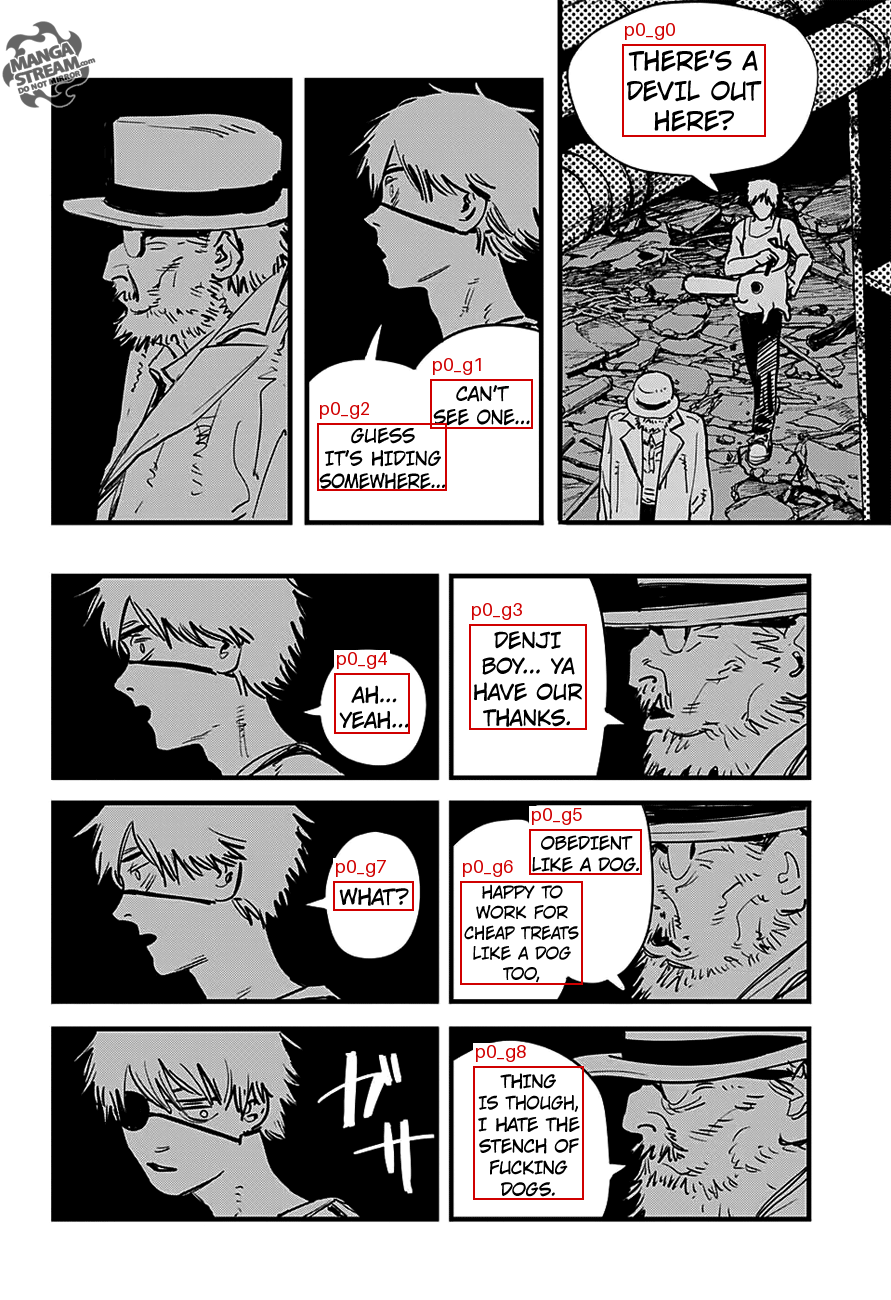

{
  "sequence_id": "seq_e8b4f75454f9491f",
  "pages": [
    [
      {
        "group_id": "p0_g0",
        "speaker": "char1"
      },
      {
        "group_id": "p0_g1",
        "speaker": "char1"
      },
      {
        "group_id": "p0_g2",
        "speaker": "char1"
      },
      {
        "group_id": "p0_g3",
        "speaker": "char2"
      },
      {
        "group_id": "p0_g4",
        "speaker": "char1"
      },
      {
        "group_id": "p0_g5",
        "speaker": "char2"
      },
      {
        "group_id": "p0_g6",
        "speaker": "char2"
      },
      {
        "group_id": "p0_g7",
        "speaker": "char1"
      },
      {
        "group_id": "p0_g8",
        "speaker": "char2"
      }
    ],
    [
      {
        "group_id": "p1_g0",
        "speaker": "char2"
      },
      {
        "group_id": "p1_g2",
        "speaker": "char2"
      }
    ],
    [
      {
        "group_id": "p2_g0",
        "speaker": "char2"
      },
      {
        "group_id": "p2_g1",
 

In [17]:
from IPython.display import display

SAMPLE = 1
PAGE = 0
image_path = OUTPUT_DIR / inputs[SAMPLE]["pages"][PAGE]["image"]
print(inputs[SAMPLE]["sequence_id"], "/ page", PAGE)
with Image.open(image_path) as image:
    display(image.copy())

print(json.dumps(targets[SAMPLE], indent=2, ensure_ascii=False))